In [44]:
import SimpleITK as sitk
from pathlib import Path
from typing import Union


In [45]:
%matplotlib inline
import matplotlib.pyplot as plt

from ipywidgets import interact, fixed
from IPython.display import clear_output
import numpy as np 
import imageio

# Callback invoked by the interact IPython method for scrolling through the image stacks of
# the two images (moving and fixed).
def display_images(fixed_image_z, moving_image_z, fixed_npa, moving_npa):
    # Create a figure with two subplots and the specified size.
    plt.subplots(1,2,figsize=(10,8))
    
    # Draw the fixed image in the first subplot.
    plt.subplot(1,2,1)
    plt.imshow(fixed_npa,cmap=plt.cm.Greys_r);
    plt.title('fixed image')
    plt.axis('off')
    
    # Draw the moving image in the second subplot.
    plt.subplot(1,2,2)
    plt.imshow(moving_npa,cmap=plt.cm.Greys_r);
    plt.title('moving image')
    plt.axis('off')
    
    plt.show()

# Callback invoked by the IPython interact method for scrolling and modifying the alpha blending
# of an image stack of two images that occupy the same physical space. 
def display_images_with_alpha(image_z, alpha, fixed, moving):
    img = (1.0 - alpha)*fixed + alpha*moving 
    plt.imshow(sitk.GetArrayViewFromImage(img),cmap=plt.cm.Greys_r);
    plt.axis('off')
    plt.show()
    
# Callback invoked when the StartEvent happens, sets up our new data.
def start_plot():
    global metric_values, multires_iterations
    
    metric_values = []
    multires_iterations = []

# Callback invoked when the EndEvent happens, do cleanup of data and figure.
def end_plot():
    global metric_values, multires_iterations
    
    del metric_values
    del multires_iterations
    # Close figure, we don't want to get a duplicate of the plot latter on.
    plt.close()

# Callback invoked when the IterationEvent happens, update our data and display new figure.
def plot_values(registration_method):
    global metric_values, multires_iterations
    
    metric_values.append(registration_method.GetMetricValue())                                       
    # Clear the output area (wait=True, to reduce flickering), and plot current data
    clear_output(wait=True)
    # Plot the similarity metric values
    plt.plot(metric_values, 'r')
    plt.plot(multires_iterations, [metric_values[index] for index in multires_iterations], 'b*')
    plt.xlabel('Iteration Number',fontsize=12)
    plt.ylabel('Metric Value',fontsize=12)
    plt.show()
    
# Callback invoked when the sitkMultiResolutionIterationEvent happens, update the index into the 
# metric_values list. 
def update_multires_iterations():
    global metric_values, multires_iterations
    
    
    
def create_unique_pixels(img):
    
    image = sitk.GetArrayViewFromImage(img)
    
    h = len(image)
    width = len(image[0])

    mask = np.zeros([h,width,3],dtype=np.uint8)
    mask.fill(0)


    for i in range(len(mask)):
        for j in range(len(mask[0])):
            mrk = image[i][j] == [0,0,0]
            mr = min(mrk) and max(mrk)
            if (not mr):
                color = i*width + j
                r = color % 256
                g = (color//256)%256
                b = ((color // 256)//256) % 256
                mask[i][j] = [r,g,b]
            else:
                mask[i][j] = [0, 0, 0]
    imageio.imwrite(outdir + "/" + "Result.jpg",mask)
    
def create_grid_image(img):
    image  = sitk.GetArrayViewFromImage(img)
    h = len(image)
    width = len(image[0])

    mask = np.zeros([h,width],dtype=np.uint8)
    mask.fill(0)
    for i in range(len(mask)):
        for j in range(len(mask[0])):

            if (image[i][j]!=0):
                if i%5 == 0 or j%5==0: 
                    mask[i][j] = 0
                else:
                    mask[i][j] = 255
            else:
                mask[i][j] = 0
    imageio.imwrite(tmpdir + "/" + "Result2.jpg",mask)
    
    
def create_image_map(init_mask, *args):
    image = sitk.GetArrayViewFromImage(init_mask)
    rex = []
    print("1   "+str(len(image)))
    print("2   "+str(len(image[0])))

    for i in range(len(image)):
        for j in range(len(image[0])):
            mr = image[i][j] != 0
            if (mr):
                pt = [i,j]
                for transf in args:
                    pt = transf.TransformPoint(pt)
                rex.append(([i,j],pt))
    return rex
              
    
    

In [46]:
fixed_image_f = Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/reference_image/oriented_image.nii.gz")
moving_image_f = Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_ablormal/Cog5_F_E64-G2766/oriented_image.nii.gz")

out_test = Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_ablormal/Cog5_F_E64-G2766/test.nii.gz")

In [47]:
fixed_image = sitk.ReadImage(fixed_image_f,sitk.sitkFloat32)
moving_image = sitk.ReadImage(moving_image_f,sitk.sitkFloat32)

# def asses_registration_quality(registered_image: Union[str,Path], reference_image: Union[str,Path]):

#     registered_image1 = sitk.ReadImage(registered_image)
#     reference_image1 = sitk.ReadImage(reference_image)

#     # Compute the DSC
#     # dsc_filter = sitk.LabelOverlapMeasuresImageFilter()
#     # dsc_filter.Execute(registered_image > 0,reference_image > 0)
#     # dsc = dsc_filter.GetDiceCoefficient()

#     print(registered_image)
#     #NX
#     sitk.NormalizedCorrelation()
#     ncc = sitk.FFTNormalizedCorrelation(registered_image1,reference_image1)
#     print(registered_image)
#     return 0,ncc

In [53]:
def register_image(fixed, moving):
    metric_values, multires_iterations = [],[]
    initial_transform = sitk.CenteredTransformInitializer(fixed, 
                                                          moving, 
                                                          sitk.Euler3DTransform(), 
                                                          sitk.CenteredTransformInitializerFilter.MOMENTS)
    registration_method = sitk.ImageRegistrationMethod()
    registration_method.SetMetricAsCorrelation()
    registration_method.SetInterpolator(sitk.sitkLinear) #2. Replace with sitkLinear
    registration_method.SetOptimizerAsGradientDescent(learningRate=0.9, numberOfIterations=100, convergenceMinimumValue=1e-6, convergenceWindowSize=10)

#     registration_method.SetOptimizerAsLBFGSB(gradientConvergenceTolerance=1e-5,
#                            numberOfIterations=20,
#                            maximumNumberOfCorrections=4,
#                            maximumNumberOfFunctionEvaluations=1000,
#                            costFunctionConvergenceFactor=1e6) #1. Increase to 1000

    # Don't optimize in-place, we would like to run this cell multiple times
    registration_method.SetInitialTransform(initial_transform,inPlace=False)
    registration_method.AddCommand(sitk.sitkIterationEvent, lambda : plot_values(registration_method))
    return registration_method.Execute(sitk.Cast(fixed_image, sitk.sitkFloat32), 
                                               sitk.Cast(moving_image, sitk.sitkFloat32))


In [ ]:
final_transform = registration_method.Execute(sitk.Cast(fixed_image, sitk.sitkFloat32), 
                                               sitk.Cast(moving_image, sitk.sitkFloat32))

In [ ]:

x = sitk.Resample(moving_image, fixed_image, final_transform, sitk.sitkLinear, 0.0, moving_image.GetPixelID())
writer = sitk.ImageFileWriter()
writer.SetFileName(str(out_test))
writer.Execute(x)

In [ ]:
moving_image = sitk.Flip(moving_image, [True, False, True])

final_transform = registration_method.Execute(sitk.Cast(fixed_image, sitk.sitkFloat32), 
                                               sitk.Cast(moving_image, sitk.sitkFloat32))


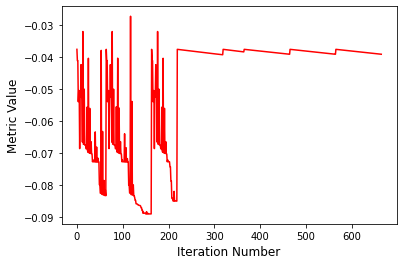

<SimpleITK.SimpleITK.CompositeTransform; proxy of <Swig Object of type 'itk::simple::CompositeTransform *' at 0x7f8ac4a6b210> >

In [54]:
register_image(fixed_image, sitk.Flip(moving_image, [True, False, True]) )
register_image(fixed_image, sitk.Flip(moving_image, [True, True, False]) )
register_image(fixed_image, sitk.Flip(moving_image, [False, True, True]) )

In [ ]:
from concurrent.futures import ProcessPoolExecutor

In [ ]:
registration_method.GetMetricValue()

In [ ]:
sitk.FlipImageFilter

In [ ]:
sitk.Flip()

In [67]:
final_transform.GetNthTransform(0).GetTranslation() 

(11.168766896959568, 13.351126075914994, 22.2336199857817)

In [69]:
final_transform.GetNthTransform(0).GetSca

(0.3448956735882659,
 -0.852027871323131,
 -0.3938216358056914,
 0.4790536654883586,
 -0.20102622899713563,
 0.8544565763322084,
 -0.8071892962138834,
 -0.4833600746273584,
 0.33883399819671334)